<a href="https://colab.research.google.com/github/bramhani007/192425319-MLA0204/blob/main/Practical_Problem_16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving iris.csv to iris (1).csv
DATASET:
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                  5.1               3.5                1.4               0.2   
1                  4.9               3.0                1.4               0.2   
2                  4.7               3.2                1.3               0.2   
3                  4.6               3.1                1.5               0.2   
4                  5.0               3.6                1.4               0.2   
..                 ...               ...                ...               ...   
145                6.7               3.0                5.2               2.3   
146                6.3               2.5                5.0               1.9   
147                6.5               3.0                5.2               2.0   
148                6.2               3.4                5.4               2.3   
149                5.9               3.0                5.1         

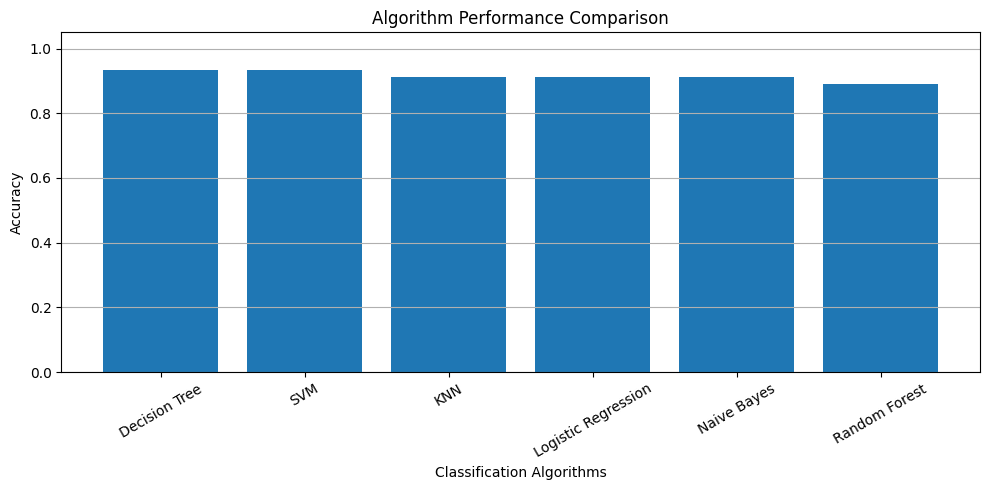

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import io
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix

# Upload dataset
uploaded = files.upload()
filename = next(iter(uploaded))
data = pd.read_csv(io.BytesIO(uploaded[filename]))

print("DATASET:")
print(data)

# Input and output
X = data.drop("target", axis=1)
y = data["target"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Define classification algorithms
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=3)
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        SVC()
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Naive Bayes": GaussianNB()
}

results = []
predictions = {}

# Train and evaluate algorithms
for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    results.append({
        "Algorithm": name,

        "Accuracy": accuracy_score(
            y_test, y_pred
        ),

        "Precision": precision_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        ),

        "Recall": recall_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        ),

        "F1 Score": f1_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        )
    })

# Create comparison table
comparison = pd.DataFrame(results)

comparison = comparison.sort_values(
    by="Accuracy",
    ascending=False
)

print("\nCLASSIFICATION ALGORITHM COMPARISON:")
print(comparison.to_string(index=False))

# Best performing model
best_model = comparison.iloc[0]["Algorithm"]

print("\nBest Performing Algorithm:")
print(best_model)

print("\nBest Accuracy:")
print(
    comparison.iloc[0]["Accuracy"] * 100,
    "%"
)

# Confusion matrix of best model
print("\nBest Model Confusion Matrix:")

print(confusion_matrix(
    y_test,
    predictions[best_model],
    labels=["setosa", "versicolor", "virginica"]
))

# Plot accuracy comparison
plt.figure(figsize=(10, 5))

plt.bar(
    comparison["Algorithm"],
    comparison["Accuracy"]
)

plt.xlabel("Classification Algorithms")
plt.ylabel("Accuracy")

plt.title("Algorithm Performance Comparison")

plt.xticks(rotation=30)
plt.ylim(0, 1.05)

plt.grid(axis="y")
plt.tight_layout()
plt.show()